In [1]:
# Notebook for eda on bronze\delhi_air_weather

In [18]:
FILE_PATH = r"D:\miniproject\data\bronze\delhi_air_weather.csv"

import pandas as pd

df = pd.read_csv(FILE_PATH)

In [19]:
# 1. Missing value analysis

# dflen = len(df)
# miss = []

# for col in df.columns:
#     missing_count = df[col].isnull().sum()
#     missing_percentage = (missing_count/dflen)*100
#     miss.append((col, round(missing_percentage, 2)))
#     #print(f"{col}\t\tMissing %={missing_percentage: .2f}%")
# sorted_miss = sorted(miss, key=lambda x: x[1])

sorted_miss = (
    df.isnull()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)
print(sorted_miss)

O Xylene (µg/m³)         100.00
Xylene (µg/m³)            98.36
MP-Xylene (µg/m³)         85.05
Eth-Benzene (µg/m³)       84.44
VWS (m/s)                 80.48
RF (mm)                   40.91
BP (mmHg)                 35.08
AT (°C)                   28.15
Toluene (µg/m³)           27.02
WS (m/s)                  24.38
SR (W/mt2)                18.41
WD (deg)                  15.68
RH (%)                    15.65
Benzene (µg/m³)           14.48
TOT-RF (mm)               13.33
SO2 (µg/m³)               10.66
NH3 (µg/m³)                9.37
PM10 (µg/m³)               5.61
PM2.5 (µg/m³)              5.24
NO2 (µg/m³)                4.35
Ozone (µg/m³)              4.29
CO (mg/m³)                 3.90
NO (µg/m³)                 3.77
NOx (ppb)                  3.43
timestamp                  0.00
station_name               0.00
latitude_x                 0.00
longitude_x                0.00
temperature_2m             0.00
relative_humidity_2m       0.00
wind_speed_10m             0.00
wind_dir

In [ ]:
# 2. Drop columns with missing percentage > 10%

cols_over_10 = sorted_miss[sorted_miss>10].index.tolist()
# print(cols_over_10)

df1 = df.drop(columns=cols_over_10)

24
40


In [74]:
#df1.columns
print(df1["station_name"].unique())

['Lodhi Road' 'Shadipur' 'ITO' 'DTU' 'R.K. Puram' 'Punjabi Bagh'
 'Dwarka Sector 8' 'Najafgarh' 'Rohini' 'Patparganj' 'Vivek Vihar'
 'Bawana' 'Mundka' 'Anand Vihar' 'Alipur']


In [76]:
df1.drop(columns=["NOx (ppb)", "precipitation"], inplace=True)

In [77]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131400 entries, 0 to 131399
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   timestamp              131400 non-null  datetime64[ns]
 1   PM2.5 (µg/m³)          124519 non-null  float64       
 2   PM10 (µg/m³)           124022 non-null  float64       
 3   NO (µg/m³)             126451 non-null  float64       
 4   NO2 (µg/m³)            125684 non-null  float64       
 5   NH3 (µg/m³)            119092 non-null  float64       
 6   CO (mg/m³)             126278 non-null  float64       
 7   Ozone (µg/m³)          125759 non-null  float64       
 8   station_name           131400 non-null  object        
 9   latitude_x             131400 non-null  float64       
 10  longitude_x            131400 non-null  float64       
 11  temperature_2m         131400 non-null  float64       
 12  relative_humidity_2m   131400 non-null  int6

In [ ]:
# #2.1 Measure missing value frequency

# gaps = []
# maxsofar = 0

# #condition = (df1[(df["station_name"]==station) & ()])

# for station in df1["station_name"].unique():
#     for val in (df1[df1["station_name"]==station]):
#         curr=0
#         if val.isnull():
#             curr+=1
#             maxsofar = max(maxsofar, curr)

200.41
253.74
241.08
153.84
86.06
83.68
98.14
104.24
112.51
120.15
127.95
129.2
116.89
132.97
137.3
170.39
156.21
153.41
132.28
120.8
104.78
109.78
144.49
144.8
127.45
86.69
94.86
94.23
95.13
80.97
96.05
90.52
94.74
124.62
144.03
171.58
166.82
152.12
121.2
152.45
144.31
182.21
161.01
131.81
152.92
174.81
177.18
177.96
120.7
151.48
147.66
146.61
122.73
126.87
131.37
117.94
150.12
115.37
137.43
163.77
280.21
335.05
401.98
222.59
187.11
185.02
153.25
154.14
157.47
169.5
174.56
244.06
261.65
194.82
194.21
163.95
180.67
150.75
137.86
103.92
121.37
151.71
208.39
211.79
313.4
359.52
310.68
329.32
250.81
221.61
197.53
214.04
198.99
204.18
197.72
193.11
201.21
160.28
127.94
101.8
102.91
81.62
96.15
119.79
105.16
102.31
92.22
108.03
121.24
125.36
152.37
114.2
132.02
134.83
179.76
184.38
185.85
180.77
140.27
121.3
141.14
154.97
140.75
121.81
90.29
88.65
71.23
70.85
97.75
188.85
200.94
176.32
165.1
154.27
145.23
104.2
132.36
128.67
124.46
126.36
111.37
127.85
127.16
126.06
106.8
101.07
91.82
84.11

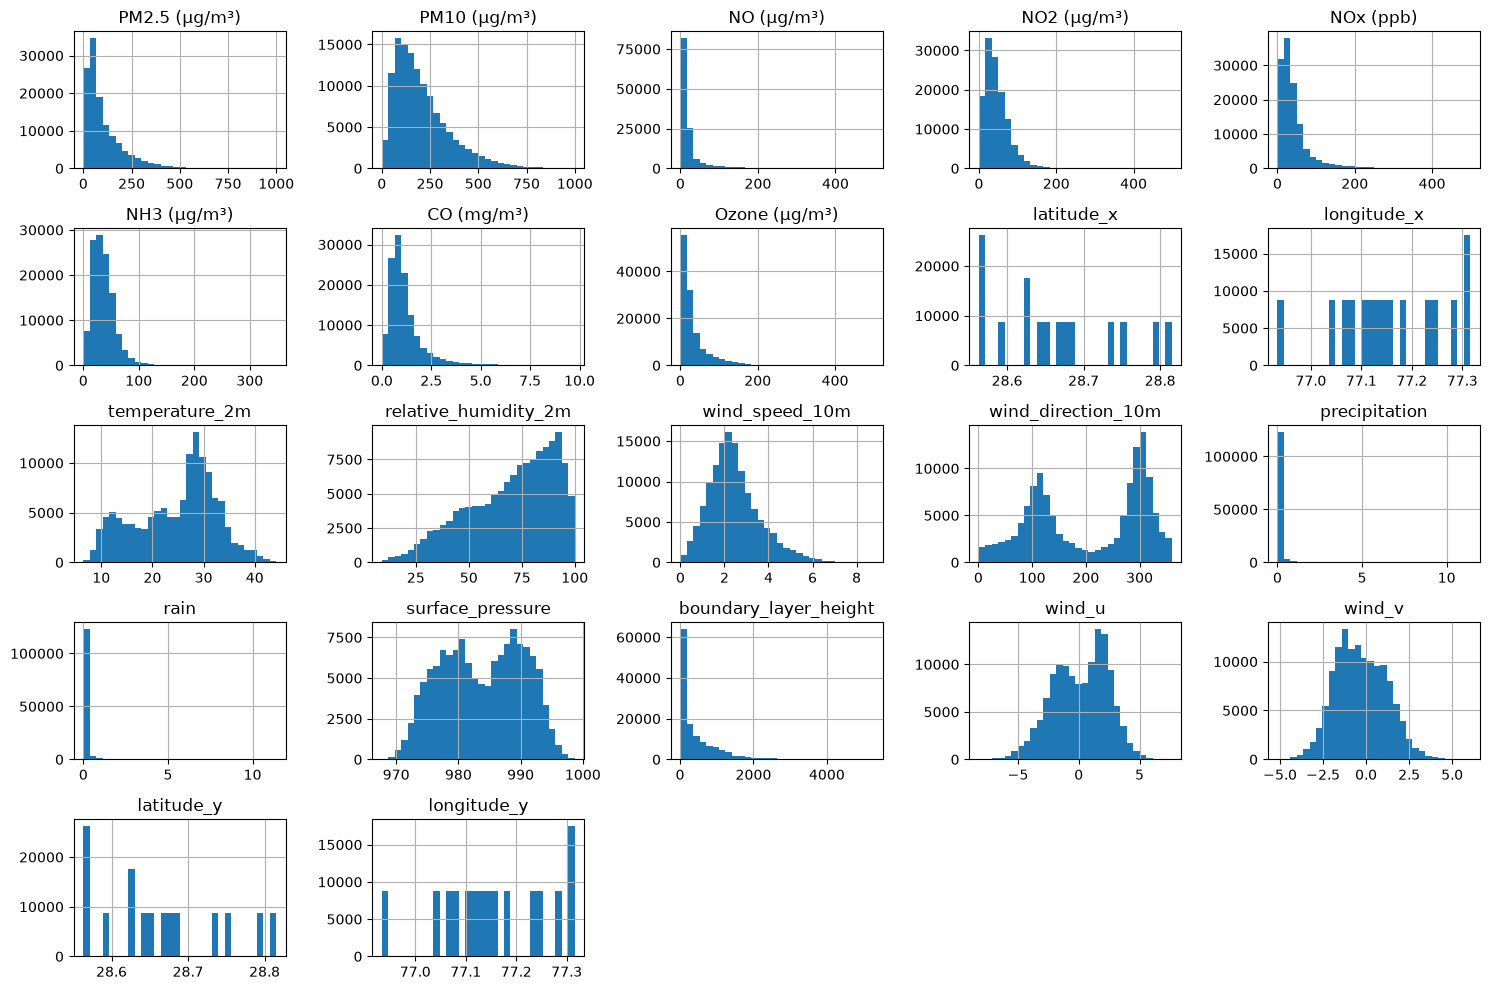

In [25]:
# 3. Univariate Analysis - Histogram - Plot histogram for each column 

import matplotlib.pyplot as plt

df1.hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

# import seaborn as sns
# import matplotlib.pyplot as plt

# # Filter down to numerical columns first
# num_cols = df1.select_dtypes(include=['number'])

# # Melt dataframe to long-form format
# df_melted = num_cols.melt()

# # Create a grid of subplots for each variable
# g = sns.FacetGrid(df_melted, col="variable", col_wrap=4, sharex=False, sharey=False)
# g.map(sns.histplot, "value", kde=True)

# plt.show()


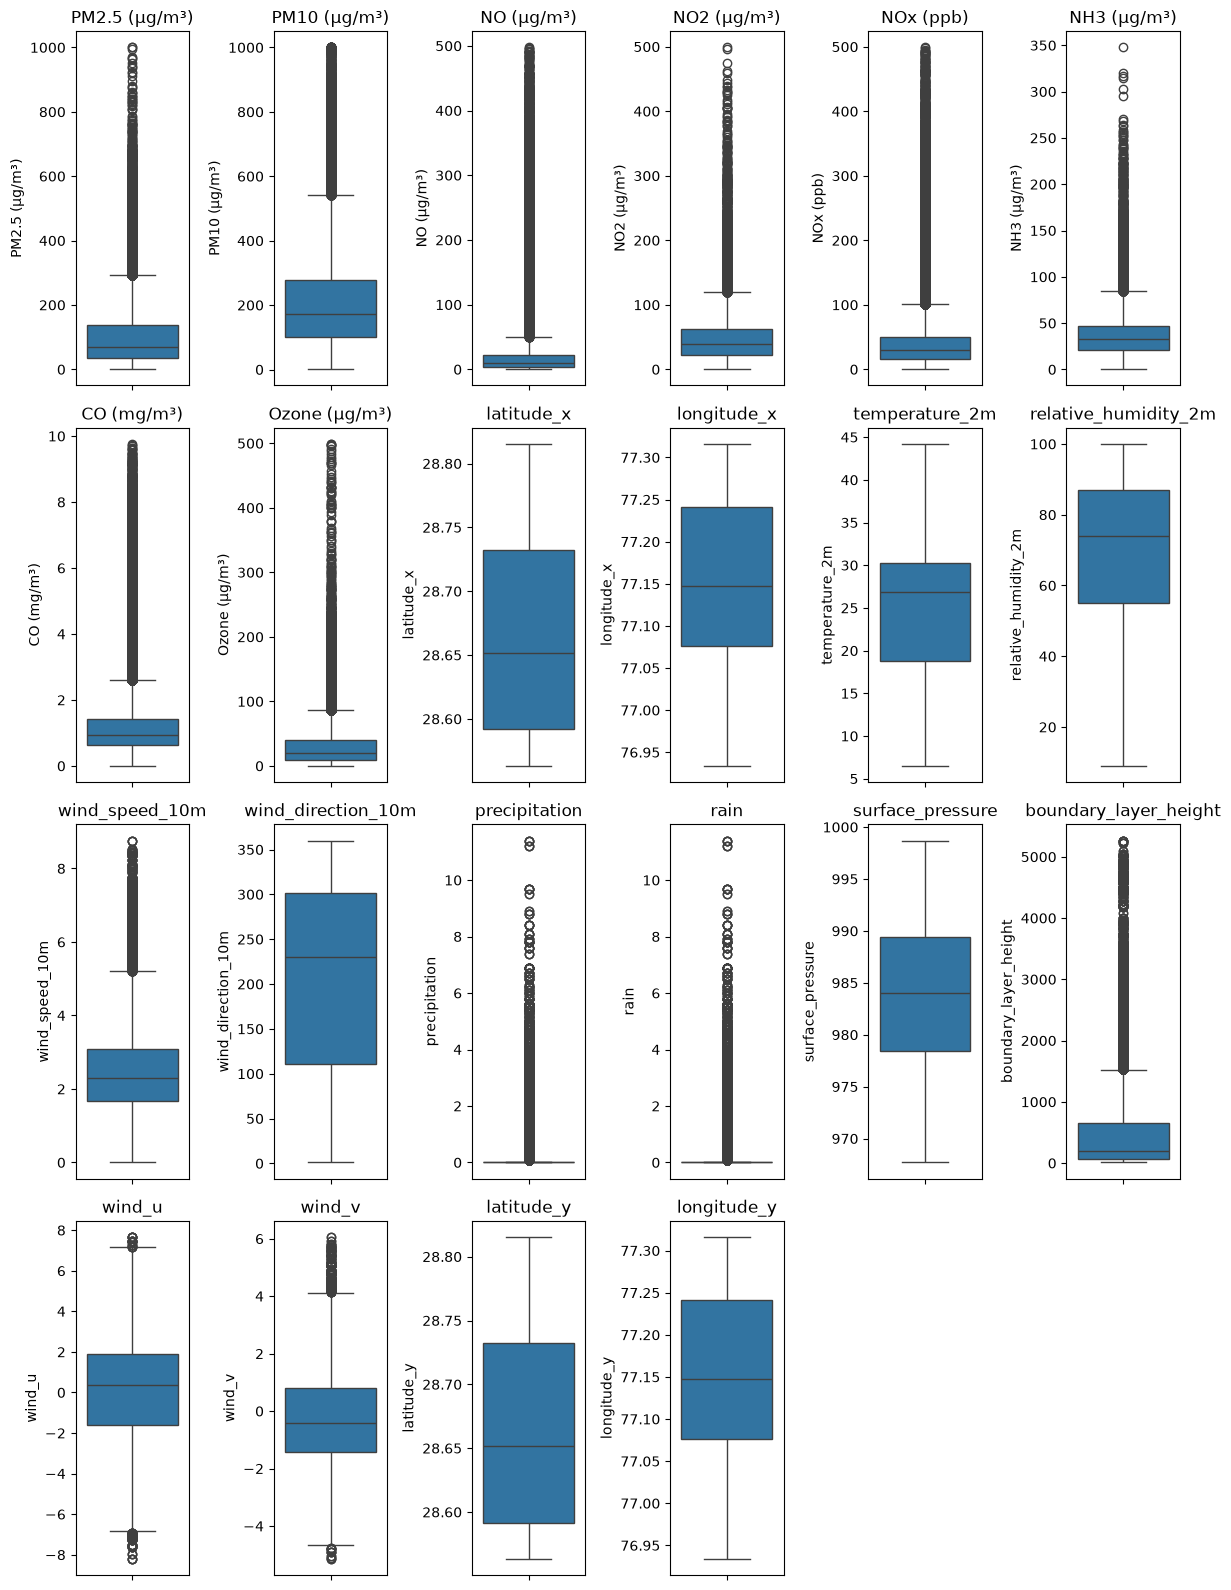

In [31]:
# 3.1. Univariate Analysis - Boxplot

import math
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df1.select_dtypes(include="number").columns

n_rows = 4
n_cols = math.ceil(len(numeric_cols) / n_rows)

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(12, 4 * n_rows),
    squeeze=False
)

# Convert the 2D axes array into a 1D array
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df1[col], ax=axes[i])
    axes[i].set_title(col)

# Hide unused subplots
for i in range(len(numeric_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_10672\604970114.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["hour"] = df2["timestamp"].dt.hour


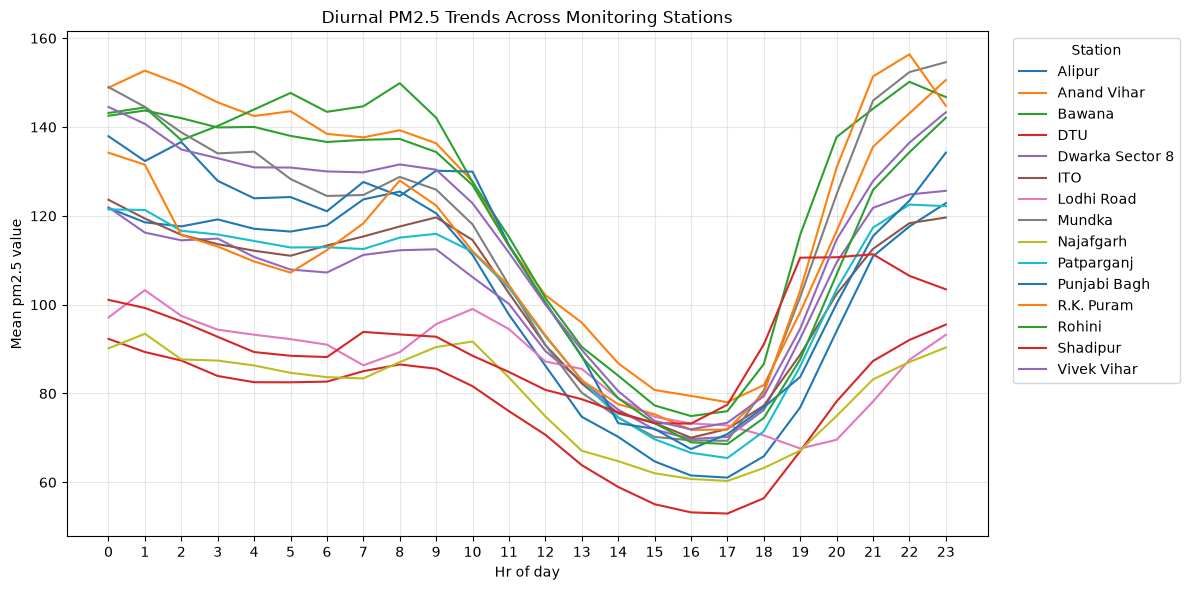

In [34]:
# 4.1 Time Series Analysis - Diurnal Trends for pm2.5 across all monitring stations

df1["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df2 = df1.dropna(subset=["timestamp", "PM2.5 (µg/m³)"])
df2["hour"] = df2["timestamp"].dt.hour

diurnal = (
    df2.groupby(["station_name", "hour"])["PM2.5 (µg/m³)"]
    .mean()
    .unstack("station_name")
    .reindex(range(24))
)

plt.figure(figsize=(12, 6))

for station in diurnal.columns:
    plt.plot(
        diurnal.index,
        diurnal[station],
        label=station
    )

plt.xticks(range(24))
plt.xlabel("Hr of day")
plt.ylabel("Mean pm2.5 value")
plt.title("Diurnal PM2.5 Trends Across Monitoring Stations")
plt.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_10672\1546380708.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["day"] = df3["timestamp"].dt.day_of_week


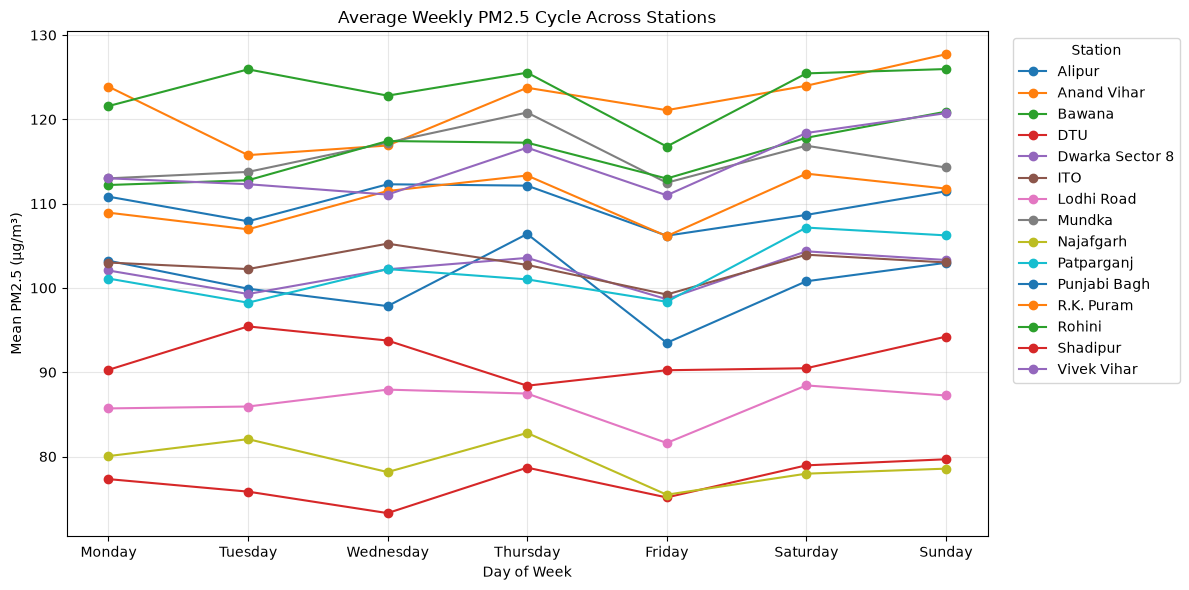

In [38]:
# 4.2 Time Series Analysis - Weekly Trends for pm2.5 across all monitring stations

df1["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df3 = df1.dropna(subset=["timestamp", "PM2.5 (µg/m³)"])
df3["day"] = df3["timestamp"].dt.day_of_week

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekly = (
    df3.groupby(["day", "station_name"])["PM2.5 (µg/m³)"]
      .mean()
      .unstack("station_name")
      .reindex(range(7))
)

weekly.index = days

# Plot
weekly.plot(figsize=(12, 6), marker="o")

plt.xlabel("Day of Week")
plt.ylabel("Mean PM2.5 (µg/m³)")
plt.title("Average Weekly PM2.5 Cycle Across Stations")
plt.grid(True, alpha=0.3)
plt.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
#plt.savefig("weekly_cycle_by_station.png", dpi=300, bbox_inches="tight")
plt.show()

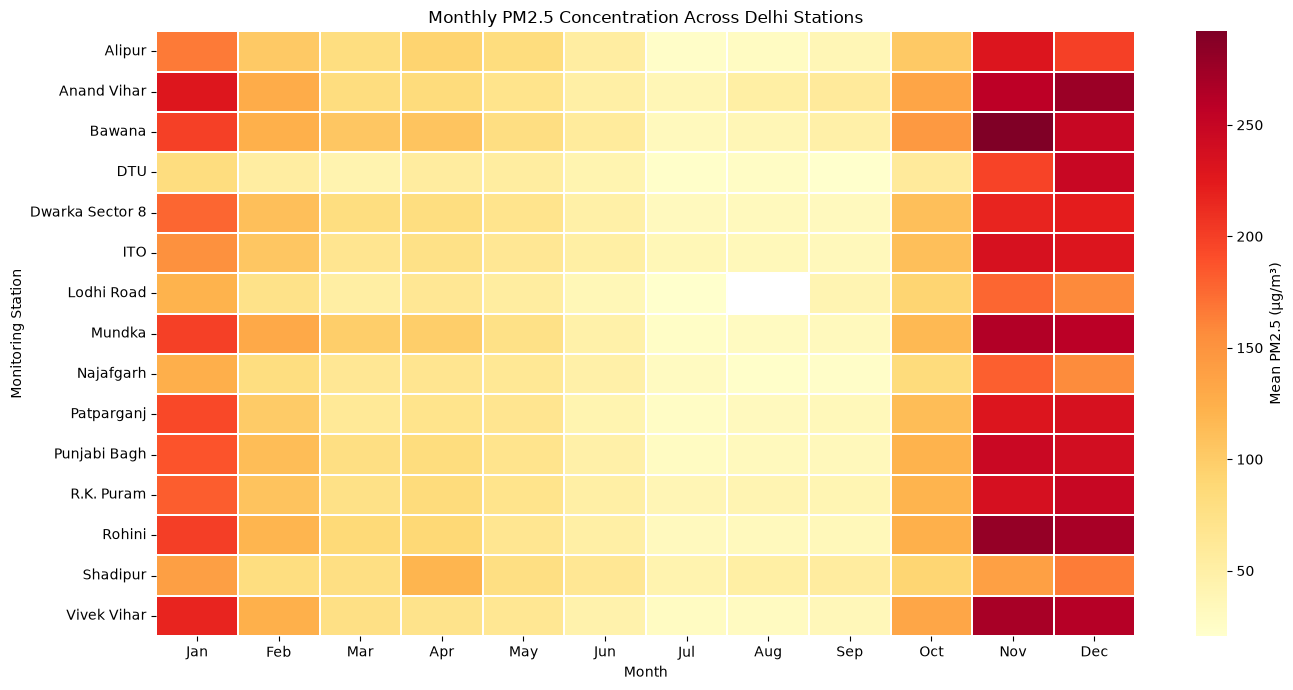

In [39]:
# 4.3 Time Series Analysis - Heatmap based monthly trends for pm2.5 across all monitring stations


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df1["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df4 = df1.dropna(subset=["timestamp", "PM2.5 (µg/m³)"])

df4 = df4.dropna(
    subset=["timestamp", "PM2.5 (µg/m³)", "station_name"]
).copy()

# Monthly mean for each station
df4["Month"] = df4["timestamp"].dt.month

monthly = df4.pivot_table(
    index="station_name",
    columns="Month",
    values="PM2.5 (µg/m³)",
    aggfunc="mean"
).reindex(columns=range(1, 13))

monthly.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(14, 7))

sns.heatmap(
    monthly,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Mean PM2.5 (µg/m³)"}
)

plt.title("Monthly PM2.5 Concentration Across Delhi Stations")
plt.xlabel("Month")
plt.ylabel("Monitoring Station")
plt.tight_layout()
plt.show()


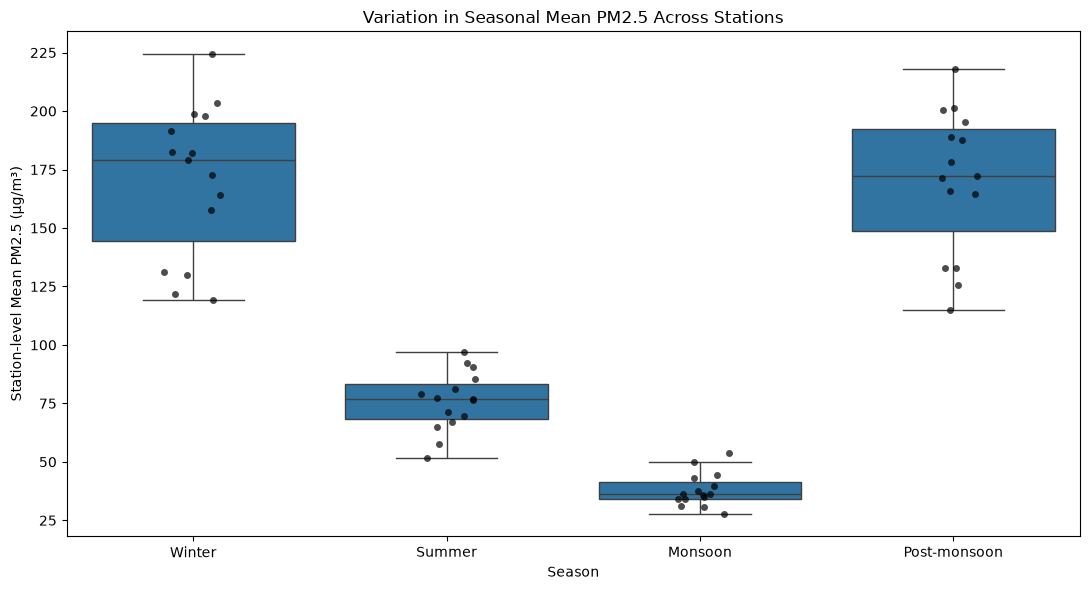

In [40]:
#4.4 Time Series Analysis - Seasonal Trends for pm2.5 by monitring stations


import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assumes df has already been loaded and cleaned
month = df4["timestamp"].dt.month

df4["Season"] = month.map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Summer",
    4: "Summer",
    5: "Summer",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-monsoon",
    11: "Post-monsoon"
})

season_order = [
    "Winter", "Summer", "Monsoon", "Post-monsoon"
]

# One mean per station per season
station_season = (
    df4.groupby(["station_name", "Season"])["PM2.5 (µg/m³)"]
      .mean()
      .reset_index()
)

# Attach the geographic zone mapping you verified
station_season["Zone"] = (
    station_season["station_name"].str.strip().str.lower()
    .map({
        # Add normalized station names and verified zones here
    })
)

# Plot individual station means within each season
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=station_season,
    x="Season",
    y="PM2.5 (µg/m³)",
    order=season_order,
    showfliers=False
)

sns.stripplot(
    data=station_season,
    x="Season",
    y="PM2.5 (µg/m³)",
    order=season_order,
    color="black",
    alpha=0.7,
    jitter=0.12
)

plt.title("Variation in Seasonal Mean PM2.5 Across Stations")
plt.xlabel("Season")
plt.ylabel("Station-level Mean PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()


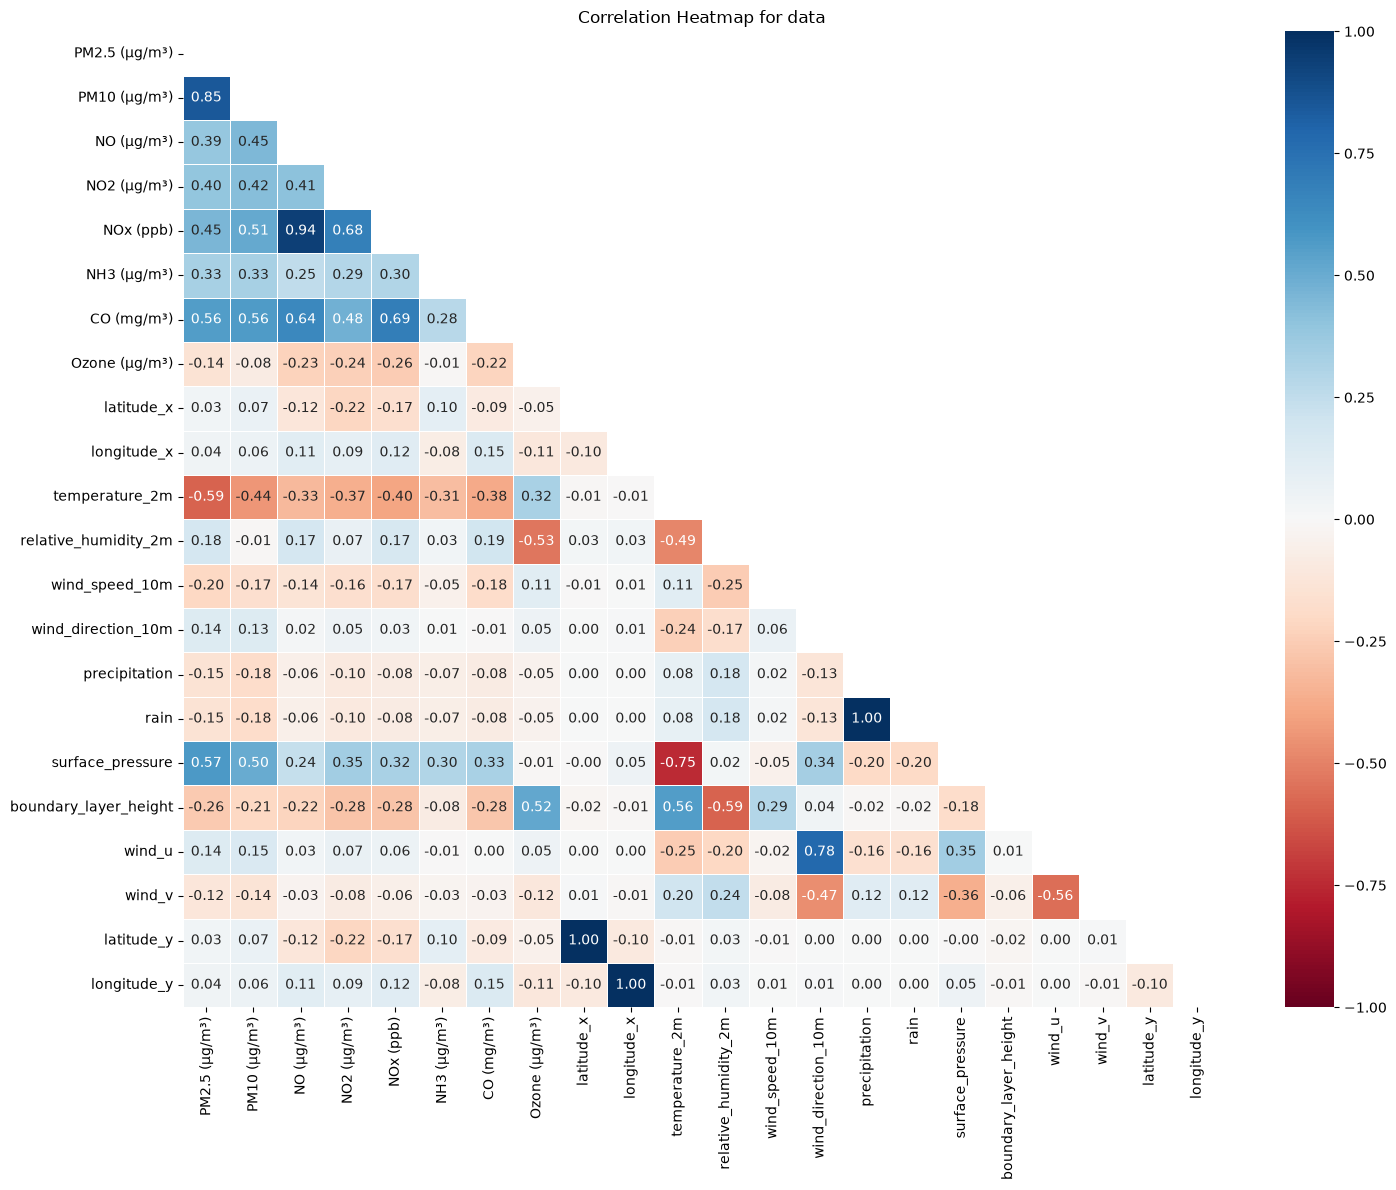

In [ ]:
# 5. Correlation heatmap for all columns
import numpy as np

corr_matrix = df1.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(15, 12))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    cmap='RdBu',
    vmin=-1, vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap for data")
plt.tight_layout()
plt.show()

#Outcome --> We have to remove rain\precipitation. We also have to remove either one of NO2\NOx. 

In [58]:
#print(df4['Season'].unique())

df_subset = df4[['latitude_x','latitude_y','longitude_x','longitude_y']]
print(df_subset)

        latitude_x  latitude_y  longitude_x  longitude_y
0          28.5918     28.5918      77.2273      77.2273
1          28.5918     28.5918      77.2273      77.2273
2          28.5918     28.5918      77.2273      77.2273
3          28.5918     28.5918      77.2273      77.2273
4          28.5918     28.5918      77.2273      77.2273
...            ...         ...          ...          ...
131395     28.8153     28.8153      77.1530      77.1530
131396     28.8153     28.8153      77.1530      77.1530
131397     28.8153     28.8153      77.1530      77.1530
131398     28.8153     28.8153      77.1530      77.1530
131399     28.8153     28.8153      77.1530      77.1530

[124519 rows x 4 columns]


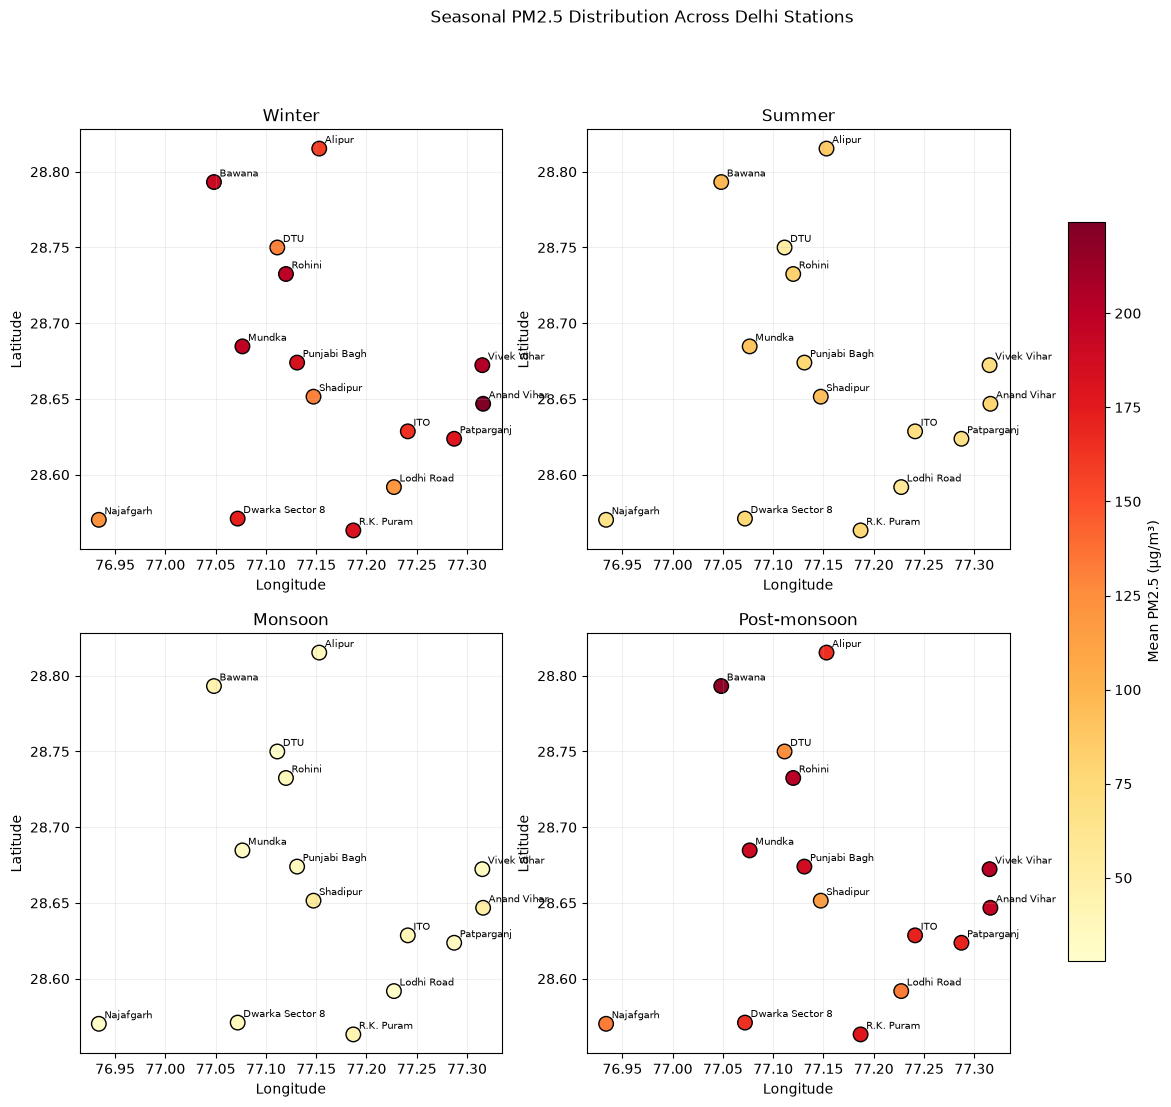

In [62]:
#6. Spatial Analysis

import pandas as pd
import matplotlib.pyplot as plt

#df = pd.read_csv("delhi_combined.csv")

df4 = df4.dropna(
    subset=["latitude_y", "longitude_y", "station_name",
            "timestamp", "PM2.5 (µg/m³)"]
).copy()

# One row per station per season
station_season = (
    df4.groupby(["station_name", "Season"])
      .agg(
          Latitude=("latitude_y", "first"),
          Longitude=("longitude_y", "first"),
          Mean_PM25=("PM2.5 (µg/m³)", "mean")
      )
      .reset_index()
)

seasons = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

# Use one common color scale for all seasons
vmin = station_season["Mean_PM25"].min()
vmax = station_season["Mean_PM25"].max()

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, season in zip(axes.flat, seasons):
    data = station_season[station_season["Season"] == season]

    scatter = ax.scatter(
        data["Longitude"],
        data["Latitude"],
        c=data["Mean_PM25"],
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        s=110,
        edgecolors="black"
    )

    for _, row in data.iterrows():
        ax.annotate(
            row["station_name"],
            (row["Longitude"], row["Latitude"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7
        )

    ax.set_title(season)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)

fig.colorbar(
    scatter,
    ax=axes.ravel().tolist(),
    label="Mean PM2.5 (µg/m³)",
    shrink=0.8
)

fig.suptitle("Seasonal PM2.5 Distribution Across Delhi Stations")
plt.show()

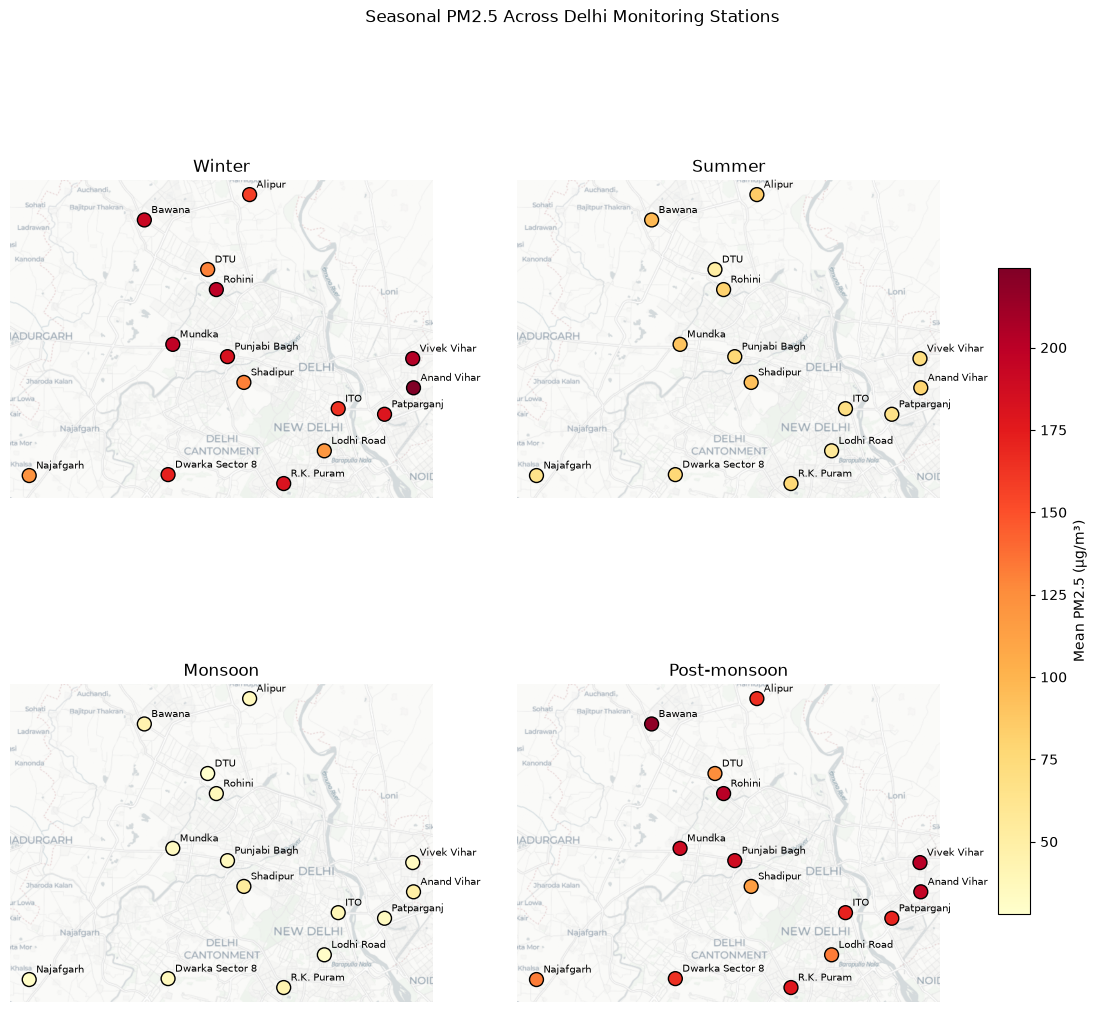

In [66]:
#6.1. Spatial Analysis on the map of delhi


import pandas as pd
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

api_key = "cb1_4ns9_1_8c1d64c728cf2bc11c47bb3c"
tile_url = (
    "https://basemaps.cartocdn.com/"
    "rastertiles/light_all/{z}/{x}/{y}.png"
    f"?key={api_key}"
)

# Clean required columns
df4 = df4.copy()

df4["PM2.5 (µg/m³)"] = pd.to_numeric(
    df4["PM2.5 (µg/m³)"], errors="coerce"
)

df4 = df4.dropna(subset=[
    "latitude_y", "longitude_y",
    "station_name", "Season", "PM2.5 (µg/m³)"
])

# One mean per station per season
station_season = (
    df4.groupby(["station_name", "Season"])
       .agg(
           Latitude=("latitude_y", "first"),
           Longitude=("longitude_y", "first"),
           Mean_PM25=("PM2.5 (µg/m³)", "mean")
       )
       .reset_index()
)

seasons = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

# Convert longitude/latitude to geographic points
gdf = gpd.GeoDataFrame(
    station_season,
    geometry=gpd.points_from_xy(
        station_season["Longitude"],
        station_season["Latitude"]
    ),
    crs="EPSG:4326"
)

# Web Mercator is required for the standard web basemap
gdf = gdf.to_crs(epsg=3857)

# Common color scale across all seasons
vmin = gdf["Mean_PM25"].min()
vmax = gdf["Mean_PM25"].max()

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, season in zip(axes.flat, seasons):
    data = gdf[gdf["Season"] == season]

    data.plot(
        ax=ax,
        column="Mean_PM25",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        markersize=100,
        edgecolor="black",
        legend=False,
        zorder=2
    )

    # Add station labels
    for _, row in data.iterrows():
        ax.annotate(
            row["station_name"],
            (row.geometry.x, row.geometry.y),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=7
        )


    ctx.add_basemap(
        ax,
        source=tile_url,
    )

    ax.set_title(season)
    ax.set_axis_off()

# Shared color scale
sm = plt.cm.ScalarMappable(
    cmap="YlOrRd",
    norm=plt.Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    label="Mean PM2.5 (µg/m³)",
    shrink=0.7
)

fig.suptitle("Seasonal PM2.5 Across Delhi Monitoring Stations")
# plt.savefig(
#     "delhi_seasonal_maps.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()


In [64]:
#6.3. Spatial Analysis using Interactive maps


import folium
import pandas as pd
import branca.colormap as cm

# Select one season
season = "Winter"

data = station_season[
    station_season["Season"] == season
].copy()

# Center map on the monitoring stations
m = folium.Map(
    location=[
        data["Latitude"].mean(),
        data["Longitude"].mean()
    ],
    zoom_start=11
)

# Shared scale for interpreting concentration
vmin = station_season["Mean_PM25"].min()
vmax = station_season["Mean_PM25"].max()

color_scale = cm.LinearColormap(
    colors=["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c"],
    vmin=vmin,
    vmax=vmax,
    caption="Mean PM2.5 (µg/m³)"
)

for _, row in data.iterrows():
    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=8,
        color="black",
        weight=1,
        fill=True,
        fill_color=color_scale(row["Mean_PM25"]),
        fill_opacity=0.85,
        tooltip=str(row["station_name"]),
        popup=(
            f"Station: {row['station_name']}<br>"
            f"Season: {season}<br>"
            f"Mean PM2.5: {row['Mean_PM25']:.2f} µg/m³"
        )
    ).add_to(m)

color_scale.add_to(m)

m.save("delhi_winter_pm25.html")


In [ ]:
#print(df4['Season'].unique())

df_subset = df4[['latitude_x','latitude_y','longitude_x','longitude_y']]
print(df_subset)

Index(['timestamp', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)',
       'NO2 (µg/m³)', 'NOx (ppb)', 'NH3 (µg/m³)', 'SO2 (µg/m³)', 'CO (mg/m³)',
       'Ozone (µg/m³)', 'Benzene (µg/m³)', 'Toluene (µg/m³)', 'Xylene (µg/m³)',
       'O Xylene (µg/m³)', 'Eth-Benzene (µg/m³)', 'MP-Xylene (µg/m³)',
       'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)', 'RF (mm)', 'TOT-RF (mm)',
       'SR (W/mt2)', 'BP (mmHg)', 'VWS (m/s)', 'station_name', 'latitude_x',
       'longitude_x', 'temperature_2m', 'relative_humidity_2m',
       'wind_speed_10m', 'wind_direction_10m', 'precipitation', 'rain',
       'surface_pressure', 'boundary_layer_height', 'wind_u', 'wind_v',
       'latitude_y', 'longitude_y'],
      dtype='object')


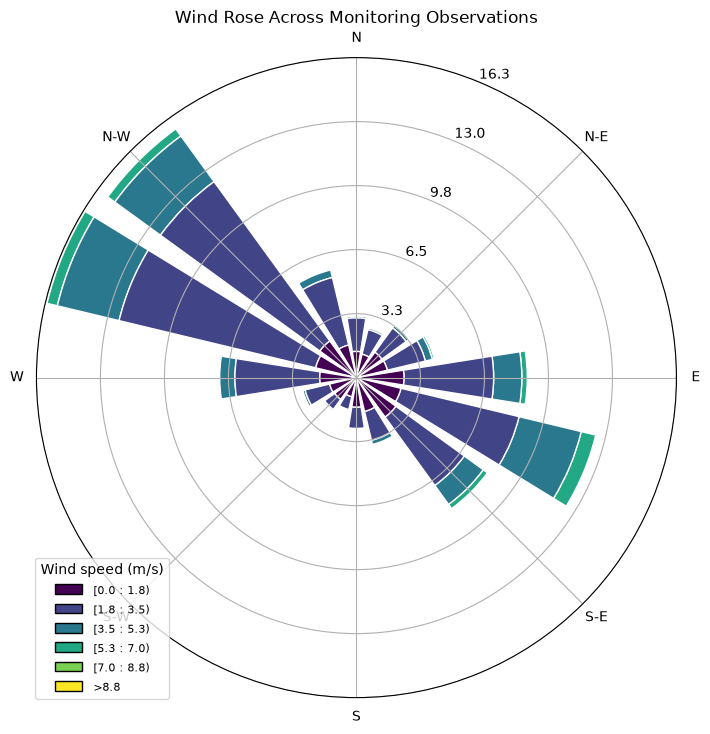

In [ ]:
# 7.1. Wind Rose plot of full dataset windspeed and wind direction to understand wind characteristics

import pandas as pd
import matplotlib.pyplot as plt
from windrose import WindroseAxes

#df = pd.read_csv("delhi_combined.csv")

# Replace with your actual column names
df4 = df4.dropna(subset=["wind_direction_10m", "wind_speed_10m"])

fig = plt.figure(figsize=(8, 8))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    df["wind_direction_10m"],
    df["wind_speed_10m"],
    normed=True,
    opening=0.8,
    edgecolor="white"
)

ax.set_legend(title="Wind speed (m/s)")
plt.title("Wind Rose Across Monitoring Observations")
plt.show()

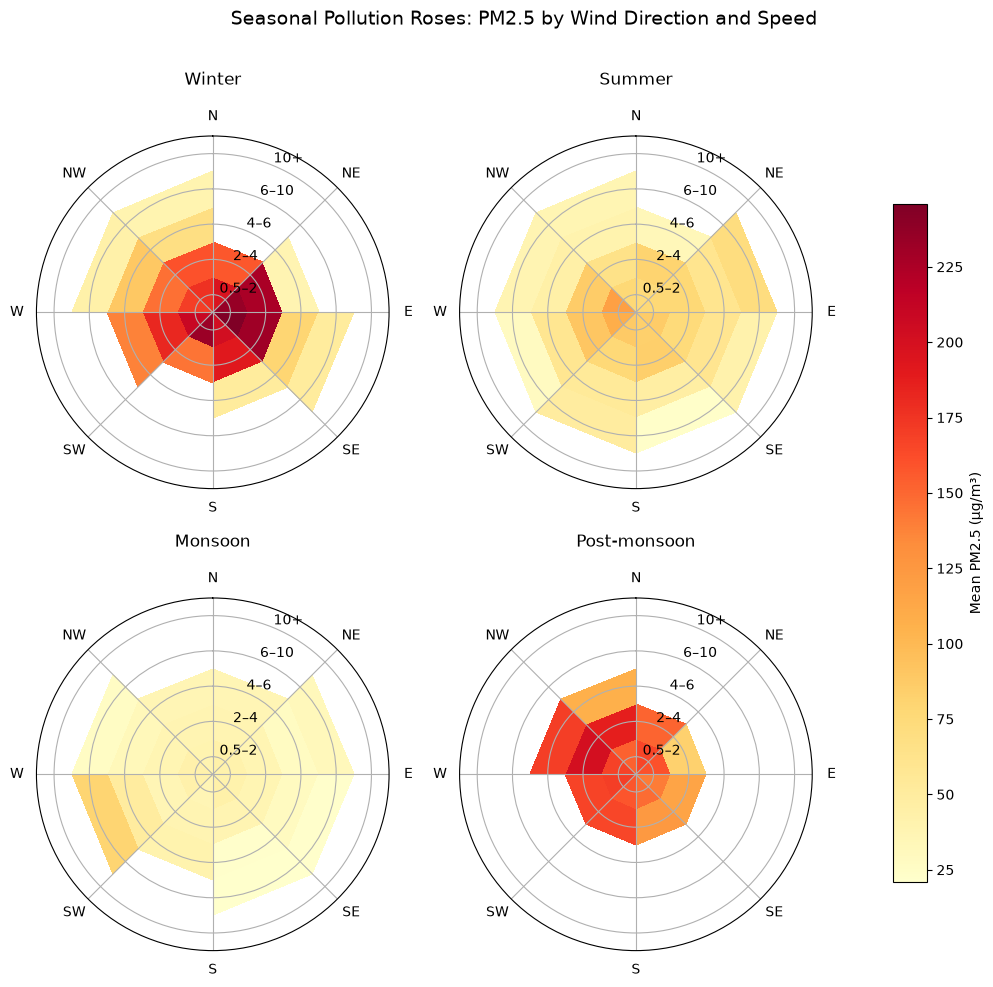

In [69]:
#7.2 Wind Rose plot of seasonal data with pm2.5 values, windspeed and wind direction to understand wind characteristics and pollution advection.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare the data
df7 = df4.copy()

for col in ["wind_u", "wind_v", "PM2.5 (µg/m³)"]:
    df7[col] = pd.to_numeric(df7[col], errors="coerce")

df7 = df7.dropna(
    subset=["wind_u", "wind_v", "PM2.5 (µg/m³)", "Season"]
).copy()

# 2. Calculate wind speed and meteorological direction
u = df7["wind_u"]
v = df7["wind_v"]

df7["Wind_Speed"] = np.sqrt(u**2 + v**2)

# Direction FROM which wind blows, in degrees clockwise from North
df7["Wind_Direction"] = (
    270 - np.degrees(np.arctan2(v, u))
) % 360

# Exclude calm winds because their direction is unreliable
df7 = df7[df7["Wind_Speed"] >= 0.5].copy()

# 3. Define wind-direction sectors and speed bins
direction_edges = np.arange(0, 361, 45)
direction_labels = [
    "N", "NE", "E", "SE", "S", "SW", "W", "NW"
]

speed_edges = [0.5, 2, 4, 6, 10, np.inf]

df7["Direction_Bin"] = pd.cut(
    df7["Wind_Direction"],
    bins=direction_edges,
    labels=direction_labels,
    include_lowest=True,
    right=False
)

# Wrap directions of 360 degrees back to North
df7["Direction_Bin"] = df7["Direction_Bin"].cat.add_categories(
    ["N"]
) if "N" not in df7["Direction_Bin"].cat.categories else df7["Direction_Bin"]

# 4. Calculate mean PM2.5 in each direction-speed combination
speed_bin = pd.cut(
    df7["Wind_Speed"],
    bins=speed_edges,
    labels=["0.5–2", "2–4", "4–6", "6–10", "10+"],
    right=False
)

df7["Speed_Bin"] = speed_bin

# Handle any direction exactly equal to 360 degrees
df7.loc[df7["Wind_Direction"] >= 360, "Direction_Bin"] = "N"

summary = (
    df7.groupby(
        ["Season", "Direction_Bin", "Speed_Bin"],
        observed=False
    )["PM2.5 (µg/m³)"]
    .mean()
    .reset_index()
)

# 5. Plot four seasonal pollution roses
seasons = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

# Use a common color scale for fair seasonal comparison
vmin = summary["PM2.5 (µg/m³)"].min()
vmax = summary["PM2.5 (µg/m³)"].max()

fig, axes = plt.subplots(
    2, 2, figsize=(13, 11),
    subplot_kw={"projection": "polar"}
)

direction_centers = np.arange(8) * 45
width = np.deg2rad(45)

for ax, season in zip(axes.flat, seasons):
    season_data = summary[summary["Season"] == season]

    # Put North at the top and directions clockwise
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    for j, speed_label in enumerate(
        ["0.5–2", "2–4", "4–6", "6–10", "10+"]
    ):
        subset = season_data[
            season_data["Speed_Bin"] == speed_label
        ].set_index("Direction_Bin")

        values = np.array([
            subset.loc[d, "PM2.5 (µg/m³)"]
            if d in subset.index else np.nan
            for d in direction_labels
        ], dtype=float)

        # Use a consistent radial extent: each sector represents
        # the mean PM2.5 for that direction-speed combination.
        theta = np.deg2rad(direction_centers)

        # Draw sectors with color encoding PM2.5.
        # The radial axis represents direction-sector index here,
        # so use a true directional heatmap instead for clarity.
        break

    # Direction × speed heatmap displayed on polar axes
    # Each angular sector is a direction; each radial band is speed.
    theta_edges = np.deg2rad(direction_edges)
    radial_edges = np.arange(len(speed_edges))

    grid = np.full((len(speed_edges) - 1, 8), np.nan)

    for i, speed_label in enumerate(
        ["0.5–2", "2–4", "4–6", "6–10", "10+"]
    ):
        for j, direction in enumerate(direction_labels):
            row = season_data[
                (season_data["Speed_Bin"] == speed_label)
                & (season_data["Direction_Bin"] == direction)
            ]
            if not row.empty:
                grid[i, j] = row["PM2.5 (µg/m³)"].iloc[0]

    mesh = ax.pcolormesh(
        theta_edges,
        radial_edges,
        grid,
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        shading="flat"
    )

    ax.set_yticks(np.arange(5) + 0.5)
    ax.set_yticklabels(["0.5–2", "2–4", "4–6", "6–10", "10+"])
    ax.set_xticks(np.deg2rad(direction_centers))
    ax.set_xticklabels(direction_labels)
    ax.set_ylim(0, 5)
    ax.set_title(season, pad=18)

fig.colorbar(
    mesh,
    ax=axes.ravel().tolist(),
    label="Mean PM2.5 (µg/m³)",
    shrink=0.8,
    pad=0.08
)

fig.suptitle(
    "Seasonal Pollution Roses: PM2.5 by Wind Direction and Speed",
    fontsize=14
)

# plt.savefig(
#     "seasonal_pm25_pollution_roses.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()


## 8. Bivariate analysis

This section examines relationships between PM2.5 and other pollutants, meteorological variables, and monitoring stations.

In [ ]:
# Bivariate analysis: PM2.5 against pollutants, weather, and station
import matplotlib.pyplot as plt
import seaborn as sns

bivariate = df1.copy()
pm25_col = next(
    (column for column in bivariate.columns if column.startswith("PM2.5")),
    None,
)
if pm25_col is None:
    raise KeyError("A PM2.5 column was not found in df1")

# Numeric relationships with PM2.5, using pairwise complete observations.
numeric_cols = bivariate.select_dtypes(include="number").columns
pm25_correlations = (
    bivariate[numeric_cols]
    .corr()[pm25_col]
    .drop(pm25_col)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
print("Correlation with PM2.5 (ordered by absolute strength):")
print(pm25_correlations.round(3).to_string())

plot_candidates = [
    column for column in [
        "PM10 (?g/m?)", "NO2 (?g/m?)", "temperature_2m",
        "relative_humidity_2m", "wind_speed_10m", "boundary_layer_height",
    ]
    if column in bivariate.columns and column != pm25_col
]
if not plot_candidates:
    plot_candidates = [
        column for column in pm25_correlations.index
        if column not in {"latitude_x", "latitude_y", "longitude_x", "longitude_y"}
    ][:4]

plot_data = bivariate[[pm25_col, *plot_candidates]].dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 10), squeeze=False)
for axis, feature in zip(axes.flat, plot_candidates[:4]):
    sns.regplot(
        data=plot_data,
        x=feature,
        y=pm25_col,
        scatter_kws={"alpha": 0.18, "s": 12},
        line_kws={"color": "crimson", "linewidth": 2},
        ax=axis,
    )
    axis.set_title(f"PM2.5 vs {feature}")
    axis.grid(alpha=0.2)
for axis in axes.flat[len(plot_candidates[:4]):]:
    axis.set_visible(False)
fig.suptitle("Bivariate Relationships with PM2.5", y=1.02)
plt.tight_layout()
plt.show()

# Categorical-numeric relationship: station-level PM2.5 distributions.
station_data = bivariate[["station_name", pm25_col]].dropna()
station_order = (
    station_data.groupby("station_name")[pm25_col]
    .median()
    .sort_values(ascending=False)
    .index
)
plt.figure(figsize=(13, 7))
sns.boxplot(
    data=station_data,
    x="station_name",
    y=pm25_col,
    order=station_order,
    showfliers=False,
)
plt.xticks(rotation=45, ha="right")
plt.title("PM2.5 Distribution by Monitoring Station")
plt.xlabel("Monitoring station")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

station_summary = (
    station_data.groupby("station_name")[pm25_col]
    .agg(mean="mean", median="median", observations="count")
    .sort_values("mean", ascending=False)
)
print("Station-level PM2.5 summary:")
print(station_summary.round(2).to_string())
